In [1]:
import torch
# torch.autograd.set_detect_anomaly(True)
from torch.utils.data import WeightedRandomSampler
from torch.utils.data import DataLoader as CNNDataLoader
from torch_geometric.loader import DataLoader as GNNDataLoader
from torch.optim.lr_scheduler import PolynomialLR
import torch.nn.functional as F
from torchvision.transforms import v2
import pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from sklearn.metrics import  classification_report
import seaborn as sns
from tqdm.notebook import tqdm
import json
from scipy.ndimage import distance_transform_edt
import cv2
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import random
import os
import zarr
from copy import deepcopy
###IE###
%load_ext autoreload
%autoreload 2
from utils.helpers import (
    read_gnn_dataset ,make_gnn_exmaple_loaders,draw_corl_matrix,
    load_model,TP_TN_FP_FN,save_cleaner_results,make_skel_from_features,
    calaculate_gnn_multi_dice,calaculate_gnn_binary_dice
)
from utils.gnn_helpers import(
    left_gnn_mapping_function
)
from utils.dataset import  (
    GnnDataset
)
from utils.preprocessing import (
    WhiteTopHat , CLAHE , normalize_xca,
    BrightnessMultiplicativeNNUNet2D,
    ContrastAugmentationNNUNet2D)
from models.gnn_model import SimpleGCN,GatGNN , VesselGraphSAGE
from models.family2_model import LCXFULL
from models.family1_model import LADFULL
from models.memory_unet import MemoryUnet
from models.side_models import Resnet50Side
from models.swin_encoder import SwinUperNet
from utils.losses import NewFocalLoss#,GnnLoss
from utils.recorder import GnnHistoryRecorder
from scripts.gnn_logger import save_full_report
from scripts.gnn_trainer import trainer
from scripts.trainer import evaluation
from scripts.image_clusters import valid,problem_maps
from scripts.gnn_feature_selection import permutation_importance, print_report
from utils.gnn_mask_drawing import draw_gnn_masks
# from models.Swin_Unet.networks.vision_transformer import  SwinUnet
###SS###

In [2]:
#2026-05-25_14-06-30 [binary-tests-dsv-clahe+frangi+swin-boot_real-erode1]
#f"left_dataset_2026-07-28_13-46-04"
gnn_generator = f"left_dataset_2026-08-14_00-05-23_3"

args = {
    "paths":{
        "base_path" : f"./dataset/syntax/gnn_dataset/{gnn_generator}",
        "output_base_path" : "./outputs",
        "features_folder" : "features",
        "edges_folder" : "edges",
        "binary_preds_folder" : "pred_masks",
        "labels_folder" : "labels",
        "multi_gt_folder":"true_masks"
    },
    "gnn_simple":{
        "hidden_channels":64,
        "use_binary_model":False,
        "th" : 0.5
    },
    "gat_simple":{
        "hidden_channels" :64 
    },
    "resent50":{
    },
    "image_shape" : (512,512),
    "in_c":3,
    "epochs":400,
    "training_mode":"multi", # side - multi - binary
    "side":"left", # both:2 , left:1 right:0
    "report_class_wise":True,
    "ensemble":False,
    "batch_size" : 10,
    "num_workers" : 2,
    "full_report_cycle":10,
    "device" : "cuda" if torch.cuda.is_available() else "cpu",
    "loss_type":"focal", 
    "name" : "full_gt_tests_branch[{}]_side[{}]",
    "mask_ce_weights":None,
    "ce_w" :None,
    "family" : ["1","2"],#"2","3","4","5","6"
    "selected_features":['x', 'y', 'geo_root', 'euc_root', 'man_root', 'reachable',"degree","radius","branch_depth"],
    ### Loss Functions
    "ce_coef":{
        "imp_coef":1.0
    },
    "focal_coef":{
        "gamma":2,
        "ignore_bg" : False,
        "alpha" : None
    },
    ### Optimizers
    "sgd_conf":{
        "lr" : 0.0001,
        "momentum" : 0.99,
        "weight_decay" : 3e-5,
        "nesterov":True
    },
    "adam_conf":{
        "lr" : 0.001,
        "weight_decay" : 3e-5,
    },
    "adamw_conf":{
        "lr" : 0.0001,
        "weight_decay" : 3e-5,
    }
}


hard_classes = [11,12,14,15,17,18,19,21,22,24,25]

with open(f"./dataset/syntax/gnn_dataset/{gnn_generator}/dataset_keys.json" , "r") as f:
    feature_keys = json.load(f)
with open(f"./dataset/syntax/gnn_dataset/{gnn_generator}/class_maps.json" , "r") as f:
    dataset_class_maps = json.load(f)
with open(f"./dataset/syntax/gnn_dataset/{gnn_generator}/extra_index_indx.json","r") as f:
    extra_index_indx = json.load(f)
old_class_maps = {}
for c in dataset_class_maps:
    old_class_maps[c] = {}
    for key,val in dataset_class_maps[c].items():
        old_class_maps[c][int(key)] = val

losses_keys = ["total loss"]
# args["ce_w"] = [3.0,1.0]

all_features = ["x","y","geo_root","euc_root","man_root","reachable","degree","branch_depth","branch_depth"] + [key for key in feature_keys if "prob" in key]
args["selected_features"] += [key for key in feature_keys if "prob" in key]
cont_features = ["x","y","geo_root","euc_root","man_root","radius"]

masking_features = ['x', 'y', 'geo_root', 'euc_root', 'man_root', 'reachable',"degree","radius","branch_depth"]

chosen_index = [feature_keys[x] for x in args["selected_features"]]

aug_args = {
    "cord_idx" : [0,1],
    "cont_idx" : [args["selected_features"].index(key) for key in cont_features if key in args["selected_features"]],
    "prob_idx": -1 ,#next((i for i, feat in enumerate(args["selected_features"]) if "prob" in feat), -1),
    "radius_idx":args["selected_features"].index("radius") if "radius" in args["selected_features"] else -1,
    "frangi_idx":args["selected_features"].index("frangi") if "frangi" in args["selected_features"] else -1,
    "masking_idx":[args["selected_features"].index(key) for key in masking_features if key in args["selected_features"]],
    "mask_prob" : 0.1,
    "e_prob":0.3,
    "g_smoother":0.3,
    "cord_smoother" : 0.3,
    "prob_smoother" : 0.3,
    "radius_smoother" : 0.3,
    "frangi_smoother" : 0.0
}

args["aug_args"] = aug_args
args["feature_size"] = len(args["selected_features"])
print("feature_keys : ",feature_keys)
print("class_maps : ",old_class_maps)
print("all_features : ",all_features)

feature_keys :  {'x': 0, 'y': 1, 'geo_root': 2, 'euc_root': 3, 'man_root': 4, 'reachable': 5, 'degree': 6, 'radius': 7, 'branch_depth': 8, 'prob_0': 9, 'prob_1': 10, 'prob_2': 11, 'prob_3': 12}
class_maps :  {'1': {0: 'bg', 1: '6', 2: '7', 3: '8', 4: '9', 5: '9a', 6: '10'}, '2': {0: 'bg', 1: '11', 2: '12', 3: '12a', 4: '13', 5: '14', 6: '14a', 7: '15', 8: '12b', 9: '14b'}, '3': {0: 'bg', 1: '5'}}
all_features :  ['x', 'y', 'geo_root', 'euc_root', 'man_root', 'reachable', 'degree', 'branch_depth', 'branch_depth', 'prob_0', 'prob_1', 'prob_2', 'prob_3']


In [ ]:
class_maps = {
    '1': {0: 'bg', 1: '6', 2: '7', 3: '8', 4: '9', 5: '9a+10'}, 
    '2': {0: 'bg', 1: '11', 2: '12', 3: '12a+12b', 4: '13', 
          5:'14', 6: '14a', 7: '15', 8: '12b', 9: '14b' },
    '3': {0: 'bg', 1: '5'}
}

In [4]:
luts = {
    "1" : left_gnn_mapping_function(old_class_maps["1"],class_maps["1"],family="1"),
    "2" : left_gnn_mapping_function(old_class_maps["2"],class_maps["2"],family="2"),
    "3" : None
}

[0 1 2 3 4 5 5] {1: 1, 2: 2, 3: 3, 4: 4, 5: 5}
[0 1 2 3 4 5 5 5 3 5] {1: 1, 2: 2, 3: 3, 4: 4, 5: 5}


In [5]:
extra_index_indx

{'1': [], '2': [], '3': []}

In [6]:
aug_args

{'cord_idx': [0, 1],
 'cont_idx': [0, 1, 2, 3, 4, 7],
 'prob_idx': -1,
 'radius_idx': 7,
 'frangi_idx': -1,
 'masking_idx': [0, 1, 2, 3, 4, 5, 6, 7, 8],
 'mask_prob': 0.1,
 'e_prob': 0.3,
 'g_smoother': 0.3,
 'cord_smoother': 0.3,
 'prob_smoother': 0.3,
 'radius_smoother': 0.3,
 'frangi_smoother': 0.0}

In [7]:
chosen_index

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

In [8]:
# class_maps = old_class_maps

In [9]:
train_images = read_gnn_dataset(
    paths = args["paths"],
    part = "train",
    chosen_index = chosen_index,
    training_mode = args["training_mode"],
    family = args["family"],
    luts = luts
)
valid_images = read_gnn_dataset(
    paths = args["paths"],
    part = "val",
    chosen_index = chosen_index,
    training_mode = args["training_mode"],
    family = args["family"],
    luts = luts
)
test_images = read_gnn_dataset(
    paths = args["paths"],
    part = "test",
    chosen_index = chosen_index,
    training_mode = args["training_mode"],
    family = args["family"],
    luts = luts
)

  0%|          | 0/625 [00:00<?, ?it/s]

625


  0%|          | 0/134 [00:00<?, ?it/s]

134


  0%|          | 0/200 [00:00<?, ?it/s]

200


  0%|          | 0/625 [00:00<?, ?it/s]

1 min max features :  -1.0 1.0
2 min max features :  -1.0 1.0
1 : Counter({0: 13668, 1: 7841, 3: 6625, 2: 5758, 4: 4549, 5: 1795})
2 : Counter({0: 9607, 5: 6417, 3: 5348, 4: 5117, 1: 4318, 2: 1338})


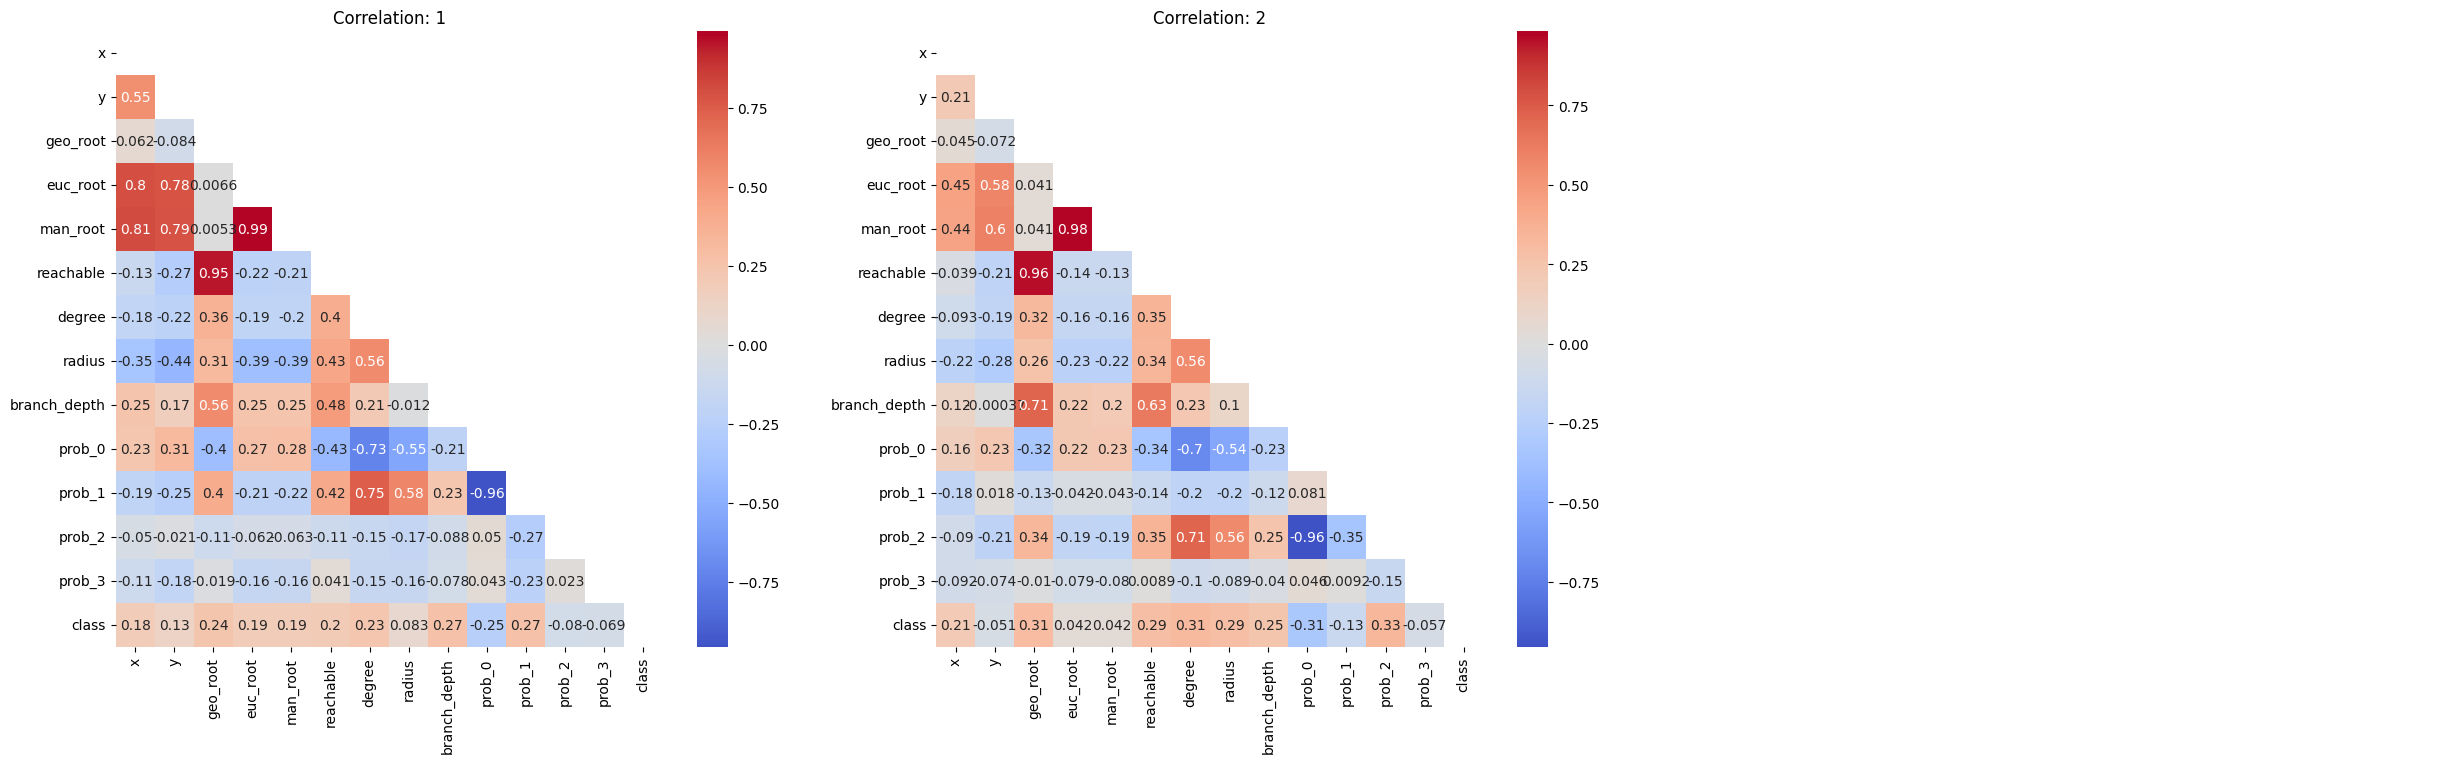

In [10]:
train_counts = draw_corl_matrix(
    train_images,
    feature_keys=args["selected_features"],
    family=args["family"],
    plot_shape=(1,3)
)

  0%|          | 0/134 [00:00<?, ?it/s]

1 min max features :  -1.0 1.0
2 min max features :  -1.0 1.0
1 : Counter({0: 1820, 1: 1094, 3: 1093, 2: 953, 4: 756, 5: 520})
2 : Counter({0: 1321, 5: 1206, 3: 745, 4: 663, 1: 656, 2: 244})


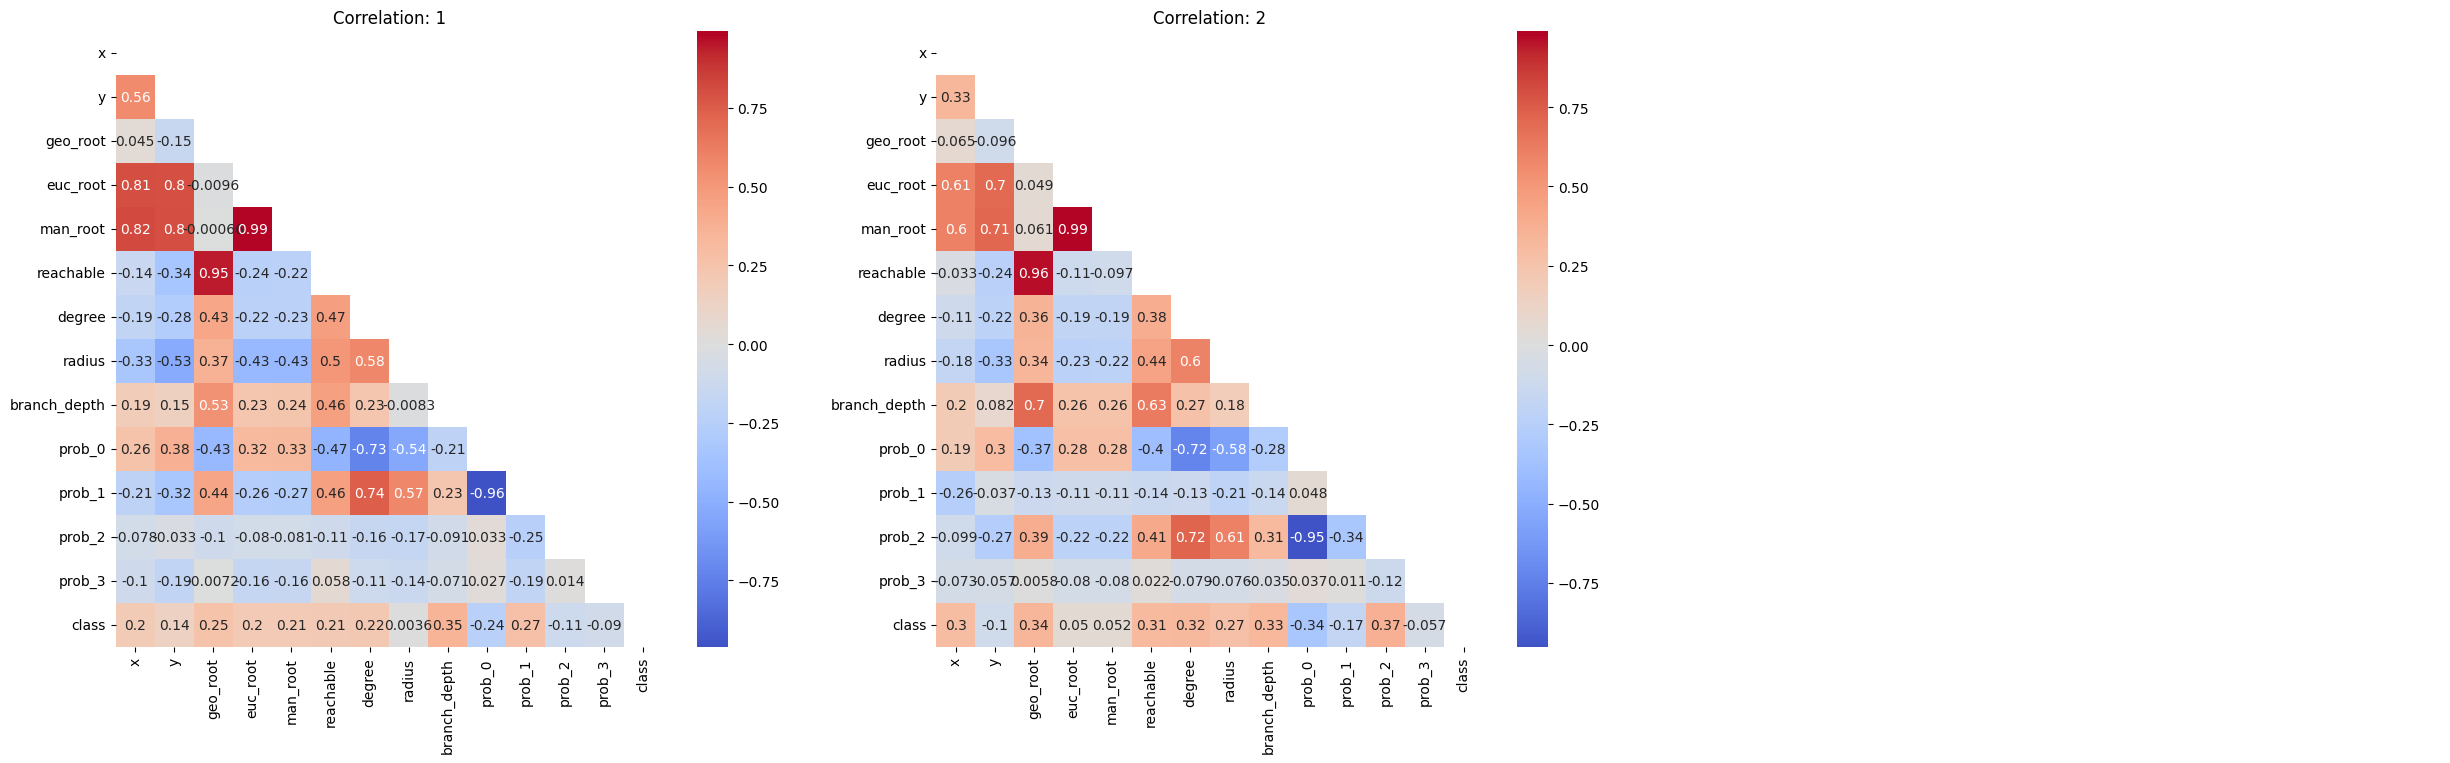

In [11]:
valid_counts = draw_corl_matrix(
    valid_images,
    feature_keys=args["selected_features"],
    family=args["family"],
    plot_shape=(1,3)
)

  0%|          | 0/200 [00:00<?, ?it/s]

1 min max features :  -1.0 1.0
2 min max features :  -1.0 1.25
1 : Counter({0: 2819, 1: 1518, 2: 1320, 4: 949, 3: 883, 5: 813})
2 : Counter({0: 2255, 5: 2035, 4: 1290, 3: 1172, 1: 1160, 2: 215})


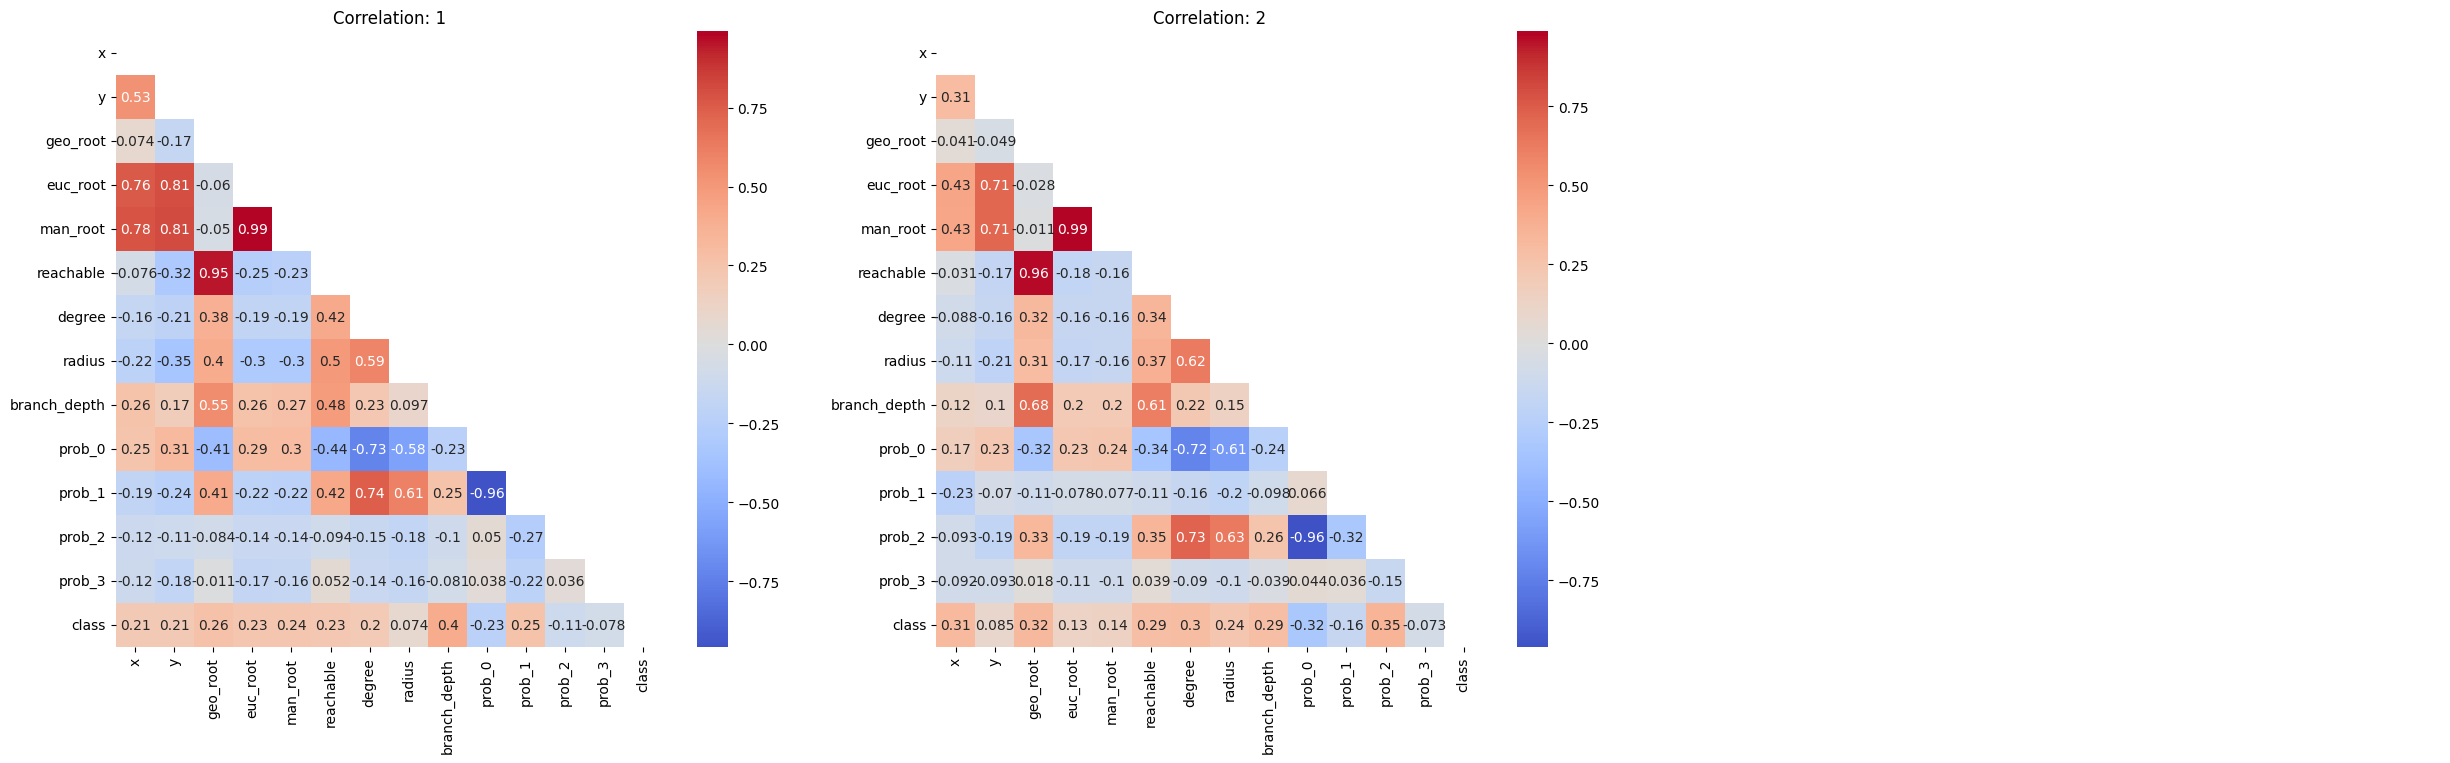

In [12]:
valid_counts = draw_corl_matrix(
    test_images,
    feature_keys=args["selected_features"],
    family=args["family"],
    plot_shape=(1,3)
)

In [12]:
ignore_index = {
    "1" : [7]
}

In [13]:
def effective_number_weights(counts, beta=0.999,ignore_bg=True):
    """counts: per-class node counts for the REAL classes only (exclude bg)."""
    if(ignore_bg):
        counts = np.asarray(counts, dtype=np.float64)[1:]
        eff = (1.0 - np.power(beta, counts)) / (1.0 - beta)
        w = 1.0 / np.clip(eff, 1e-8, None)
        w = w / w.sum() * len(counts)
        w = w.tolist()
        return [0.0, *w]
    else:
        counts = np.asarray(counts, dtype=np.float64)
        eff = (1.0 - np.power(beta, counts)) / (1.0 - beta)
        w = 1.0 / np.clip(eff, 1e-8, None)
        w = w / w.sum() * len(counts)
        w = w.tolist()
        # return [0.0, *w]
        return w

family_weights = {}
for c,train_counts_c in train_counts.items():
    if(len(train_counts_c)!=len(class_maps[c])):
        for i in range(len(class_maps[c])):
            if(i not in train_counts_c):
          
                train_counts_c[i] = max(train_counts_c.values())*10
    counts = [0]*len(train_counts_c) 
    for i in range(len(counts)):
        counts[i] = train_counts_c[i]
    print(train_counts_c)
    weights = effective_number_weights(counts, beta=0.99999,ignore_bg = args["focal_coef"]["ignore_bg"])
    if(c == "4"):
        weights[1] = 1.0
    if(c == "1"):
        # weights[-2] = 0.0001
        # weights[-1] = 0.001
        pass
    family_weights[c] = weights
    print(f"weights for family {c} : ",weights)


Counter({0: 9607, 5: 6417, 3: 5348, 4: 5117, 1: 4318, 2: 1338})
weights for family 2 :  [0.39660497305188114, 0.8596300628443168, 2.7333648124781993, 0.6976240544968628, 0.7282830296509938, 0.5844930674777461]


In [14]:
# family_weights["1"] = [0.0,1.0,1.0,1.0,1.0,1.0,2.9,0.0,0.2]

In [15]:
def get_dataloaders(
    train_images,
    valid_images,
    test_images,
    DataLoader,
    family,
    aug_args,
    args):

    train_ds = GnnDataset(
        data = train_images, 
        part = "train",
        training_mode=args["training_mode"],
        aug_args=aug_args,
        family=family
    )
    valid_ds = GnnDataset(
        data = valid_images, 
        part = "val",
        training_mode=args["training_mode"],
        family=family
    )
    test_ds = GnnDataset(
        data = test_images, 
        part = "test",
        training_mode=args["training_mode"],
        family=family
    )



    train_loader = DataLoader(
        train_ds,
        batch_size = args["batch_size"] ,
        num_workers = 0 ,#args["num_workers"] ,
        pin_memory=True,
        shuffle=True
    )
    valid_loader = DataLoader(
        valid_ds,
        batch_size = 1 ,
        pin_memory=True,
        shuffle=False,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size = 1  ,
        pin_memory=True,
        shuffle=False,
    )
    return train_loader , valid_loader , test_loader , DataLoader

In [16]:
results = {}
for family in tqdm(args["family"]) : 

    train_loader , valid_loader , test_loader , DataLoader = get_dataloaders(
        train_images = train_images,
        valid_images = valid_images,
        test_images = test_images,
        DataLoader = GNNDataLoader,
        family=family,
        args=args,
        aug_args=aug_args
    )
    args[f"class_maps_{family}"] = class_maps[family]
    args[f"class_count_{family}"] = len(class_maps[family])
    args[f"class_count"] = len(class_maps[family])
    recorder = GnnHistoryRecorder(
        losses_keys = losses_keys,
        class_count = args[f"class_count_{family}"] ,
        training_mode = args["training_mode"]
    )
    print(f"training gnn mullti model for family {family}")
    # model = SimpleGCN(args).to(args["device"])
    model = VesselGraphSAGE(args).to(args["device"])
    optimizer = torch.optim.Adam(model.parameters(),**args["adam_conf"])

    args["focal_coef"]["alpha"] = family_weights[family]
    # optimizer = torch.optim.SGD(model.parameters(),**args["sgd_conf"])
    # loss_fn = GnnLoss(args)
    loss_fn =  NewFocalLoss(args["focal_coef"])
    lr_sch = None

    best_model = trainer(
        args=args,
        recorder = recorder,
        model = model,
        optimizer = optimizer,
        loss_fn = loss_fn,
        train_loader = train_loader,
        valid_loader = valid_loader,
        lr_sch = lr_sch
    )
    results [family] = {
        "model" : best_model.eval(),
        "recorder" : deepcopy(recorder)
    }

  0%|          | 0/1 [00:00<?, ?it/s]

total of 395 for family 2
total of 94 for family 2
total of 146 for family 2
training gnn mullti model for family 2


  0%|          | 0/400 [00:00<?, ?it/s]

train [0]:
losses :total loss:0.80342|
metrics: f1:0.28941|per:0.31321|rec:0.31057
val [0]:
losses :total loss:0.79366|
metrics: f1:0.46515|per:0.47224|rec:0.50618
++++++++++++++++++++++++++++++++++++++++++++
New Best! : F1 = 0.4651532946053245
train [1]:
losses :total loss:0.67051|
metrics: f1:0.37986|per:0.39174|rec:0.40465
val [1]:
losses :total loss:0.74288|
metrics: f1:0.47616|per:0.49021|rec:0.51622
++++++++++++++++++++++++++++++++++++++++++++
New Best! : F1 = 0.4761626381321899
train [2]:
losses :total loss:0.63602|
metrics: f1:0.40078|per:0.41366|rec:0.42827
val [2]:
losses :total loss:0.68931|
metrics: f1:0.48185|per:0.50272|rec:0.51981
++++++++++++++++++++++++++++++++++++++++++++
New Best! : F1 = 0.4818478595305263
train [3]:
losses :total loss:0.62203|
metrics: f1:0.40418|per:0.41501|rec:0.43510
val [3]:
losses :total loss:0.67440|
metrics: f1:0.49245|per:0.49531|rec:0.52684
++++++++++++++++++++++++++++++++++++++++++++
New Best! : F1 = 0.49245181465235377
train [4]:
losses :

In [17]:
# args[f"class_maps_2"] = class_maps["2"]
# args[f"class_count_2"] = len(class_maps["2"])
# recorder = GnnHistoryRecorder(
#     losses_keys = losses_keys,
#     class_count = args[f"class_count_2"] ,
#     training_mode = args["training_mode"]
# )
# results = {
#     "1":{
#         "model" : LADFULL(args).eval(),
#         "recorder" : deepcopy(recorder)
#     },
#     "2":{
#         "model" : load_model(
#             model_class= VesselGraphSAGE,
#             model_name="model_2",
#             path="./outputs/2026-08-18_01-10-02 [full_gt_tests_branch[2]_side[left]]",
#             device = "cuda",
#             model_inputs={},
#             task_type="gnn"
#         ),
#         "recorder" : deepcopy(recorder)
#     },
#     "3":{
#         "model" : load_model(
#             model_class= VesselGraphSAGE,
#             model_name="model_3",
#             path="./outputs/2026-08-18_12-22-02 [full_gt_tests_branch[3]_side[left]]",
#             device = "cuda",
#             model_inputs={},
#             task_type="gnn"
#         ),
#         "recorder" : deepcopy(recorder)
#     }
# }

In [18]:
# example_dataloaders_family = {}
# for family in args["family"]:
#     example_dataloaders = make_gnn_exmaple_loaders(
#         args=args,
#         train_images=train_images,
#         valid_images=valid_images,
#         Example_DL = GNNDataLoader,
#         family = family
#     )
#     example_dataloaders_family [family] = example_dataloaders

In [19]:
# calaculate_dataset_quality(
#     dataloaders=example_dataloaders,
#     paths=args["paths"],
#     class_count=args["class_count"],
#     use_binary_model = args["gnn_simple"]["use_binary_model"]
# )

In [20]:
f = "_".join(args["family"])
args["name"] = args["name"].format(f,args["side"])
args["name"] 

'full_gt_tests_branch[2]_side[left]'

In [21]:
# results = {}
# for family in args["family"]:
#     args["class_count"] = len(class_maps[family])
#     pth = torch.load(f"./outputs/2026-08-07_00-04-58 [full_gt_tests_branch[1_2_3_4_5_6]_side[left]]/model_{family}.pth",weights_only=False)
#     best_model = VesselGraphSAGE(args)
#     best_model.load_state_dict(pth)
#     best_model = best_model.to("cuda")
#     best_model.eval()
#     results [family] = {
#         "model" : best_model.eval(),

#     }

In [22]:
restult_sets = {
    "train":{
        "gnn_preds":{},
        "cnn_vessels":{},
        "gt_vessels":{},
        "real_labels":{}
    },
    "val":{
        "gnn_preds":{},
        "cnn_vessels":{},
        "gt_vessels":{},
        "real_labels":{}
    }
}
models_label_predictions = {
    "train":{str(c):{"pred":[],"true":[]} for c in args["family"]},
    "val":{str(c):{"pred":[],"true":[]} for c in args["family"]}
}
images = {
    "train" : train_images,
    "val" : valid_images
}
with torch.no_grad():
    for part,images in images.items():
        for data in tqdm(images) :
            if(len(data["correct"]["features"]) == 0 and len(data["missed"]["gts"]) == 0):
                continue
            name = data["name"]
            restult_sets[part]["gnn_preds"][name] = {}
            restult_sets[part]["cnn_vessels"][name] = {}
            restult_sets[part]["gt_vessels"][name] = {}
            for c in data["correct"]["features"]:
                c = str(c)
                model = results[c]["model"].eval()
                f_t = data["correct"]["features"][c].copy()
                e_t = data["correct"]["edges"][c].copy()
                f_t = torch.from_numpy(f_t).float().cuda()
                e_t = torch.from_numpy(e_t).int().cuda()

                with torch.autocast("cuda"):
                    pred_labels = model(f_t,e_t)
                    if(c != "1"):
                        pred_labels = torch.argmax(pred_labels,dim=1)
                    pred_labels = pred_labels.cpu().numpy()
                
                restult_sets[part]["gnn_preds"][name][c] = [pred_labels , data["correct"]["features"][c]]
                restult_sets[part]["cnn_vessels"][name][c] = data["correct"]["preds"][c]
                restult_sets[part]["gt_vessels"][name][c] = data["correct"]["gts"][c]

                models_label_predictions[part][c]["pred"] += pred_labels.tolist()
                models_label_predictions[part][c]["true"] += data["correct"]["labels"][c].tolist()

            for c in data["extra"]["features"]:
                c = str(c)
                restult_sets[part]["gnn_preds"][name][c] = [data["extra"]["labels"][c] , data["correct"]["features"][c]]
                restult_sets[part]["cnn_vessels"][name][c]  = data["extra"]["preds"][c]
                restult_sets[part]["gt_vessels"][name][c] = data["extra"]["gts"][c]

            for c in data["missed"]["gts"] : 
                c = str(c)
                restult_sets[part]["gt_vessels"][name][c] = data["missed"]["gts"][c]
                

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/134 [00:00<?, ?it/s]

In [23]:
# draws = draw_gnn_masks(
#     gnn_preds = restult_sets["val"]["gnn_preds"],
#     cnn_vessels = restult_sets["val"]["cnn_vessels"],
#     gt_vessels = restult_sets["val"]["gt_vessels"],
#     family_labels = class_maps
# )
# os.makedirs(Path(args["paths"]["base_path"]) / "gnn_predictions_mask_plots",exist_ok=True)
# for name, canvas in draws.items():
#     cv2.imwrite(Path(args["paths"]["base_path"])  / "gnn_predictions_mask_plots" / f"{name}.png",canvas)

In [24]:
from utils.gnn_evaluation import evaluate_merged
overall, per_class = evaluate_merged(
    gnn_preds = restult_sets["val"]["gnn_preds"],
    cnn_vessels = restult_sets["val"]["cnn_vessels"],
    gt_vessels = restult_sets["val"]["gt_vessels"] ,
    family_labels = class_maps
)
overall , per_class

(0.3969237978645794,
 {'11': 0.6997243624874794,
  '12': 0.19862272207851708,
  '12a+12b': 0.38506362230940744,
  '13': 0.5675410146988878,
  '14+14a+15+14b': 0.13366726774860524})

outputs/2026-08-25_17-16-44 [full_gt_tests_branch[2]_side[left]]
==================>processing [2]<==================
Save Model
Saving Memory
generate report
{0: 'bg', 1: '11', 2: '12', 3: '12a+12b', 4: '13', 5: '14+14a+14b+15'}
train evaluation Report
=+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+=
               precision    recall  f1-score   support

           bg       0.75      0.48      0.58      9607
           11       0.77      0.82      0.80      4318
           12       0.33      0.74      0.46      1338
      12a+12b       0.49      0.56      0.52      5348
           13       0.62      0.70      0.66      5117
14+14a+14b+15       0.48      0.50      0.49      6417

     accuracy                           0.59     32145
    macro avg       0.58      0.63      0.59     32145
 weighted avg       0.62      0.59      0.59     32145

val evaluation Report
=+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+==+

,dice,index
0,0.736092,11
1,0.399962,12
2,0.355799,12a+12b
3,0.614314,13
4,0.144710,14+14a+15+14b
5,0.450175,overall


{'1': {0: 'bg', 1: '6', 2: '7', 3: '8', 4: '9', 5: '9a+10'}, '2': {0: 'bg', 1: '11', 2: '12', 3: '12a+12b', 4: '13', 5: '14+14a+14b+15'}, '3': {0: 'bg', 1: '5'}}
{'dice': [0.6997243624874794, 0.19862272207851708, 0.38506362230940744, 0.5675410146988878, 0.13366726774860524, 0.3969237978645794], 'index': ['11', '12', '12a+12b', '13', '14+14a+15+14b', 'overall']}
0.3969237978645794 {'11': 0.6997243624874794, '12': 0.19862272207851708, '12a+12b': 0.38506362230940744, '13': 0.5675410146988878, '14+14a+15+14b': 0.13366726774860524, 'overall': 0.3969237978645794}
dice for val


,dice,index
0,0.699724,11
1,0.198623,12
2,0.385064,12a+12b
3,0.567541,13
4,0.133667,14+14a+15+14b
5,0.396924,overall


builfding kaggle project


100%|██████████| 15/15 [00:00<00:00, 2825.08it/s]


processing ./utils/dataset.py
processing ./utils/helpers.py
processing ./scripts/gnn_logger.py
processing ./utils/recorder.py
processing ./utils/graph_extraction.py
processing ./models/gnn_model.py
processing ./utils/losses.py
processing ./scripts/gnn_trainer.py
processing ./utils/k_step_graph_extraction_left.py
processing ./utils/k_step_graph_extraction.py
processing ./scripts/make_gnn_dataset.py
processing ./scripts/make_left_gnn_dataset.py
processing ./utils/gnn_dataset_generation_args.py
processing ./utils/gnn_dataset_generation_left_args.py
processing ./utils/gnn_helpers.py


100%|██████████| 1/1 [00:00<00:00,  1.78it/s]

processing ./temp_script.py


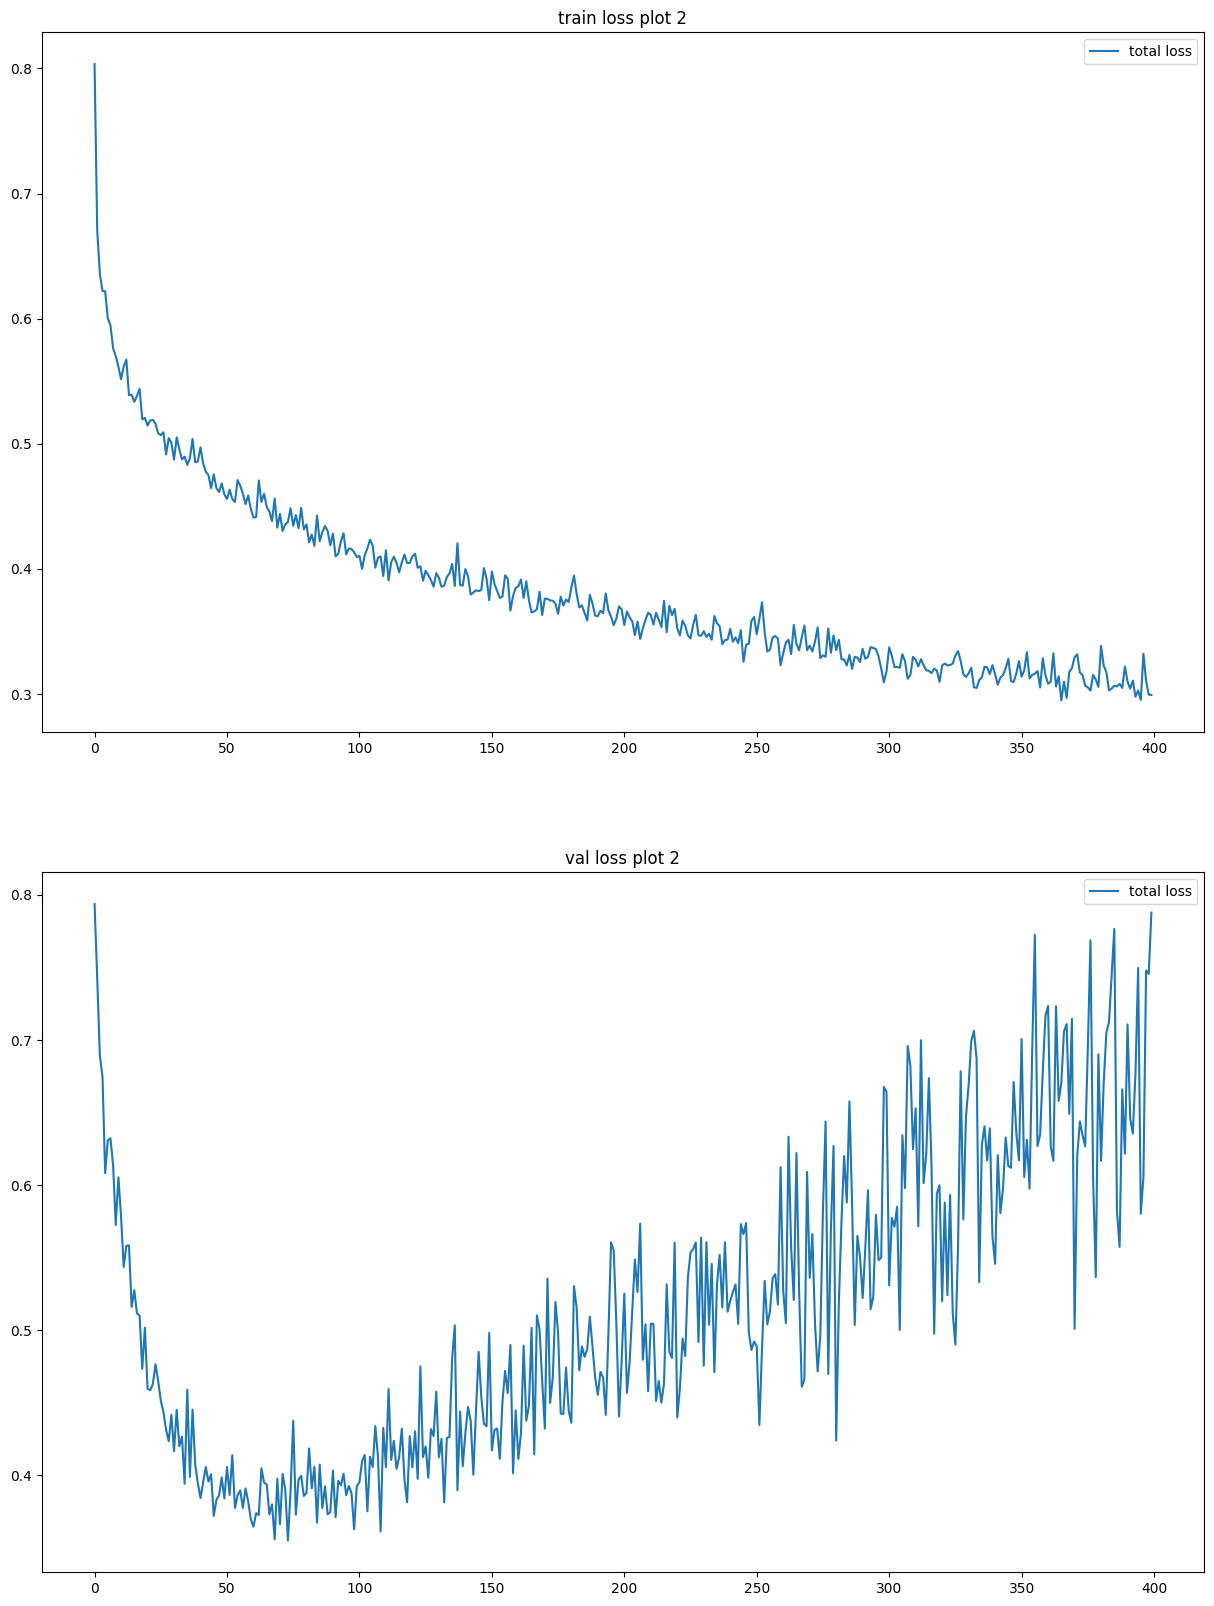

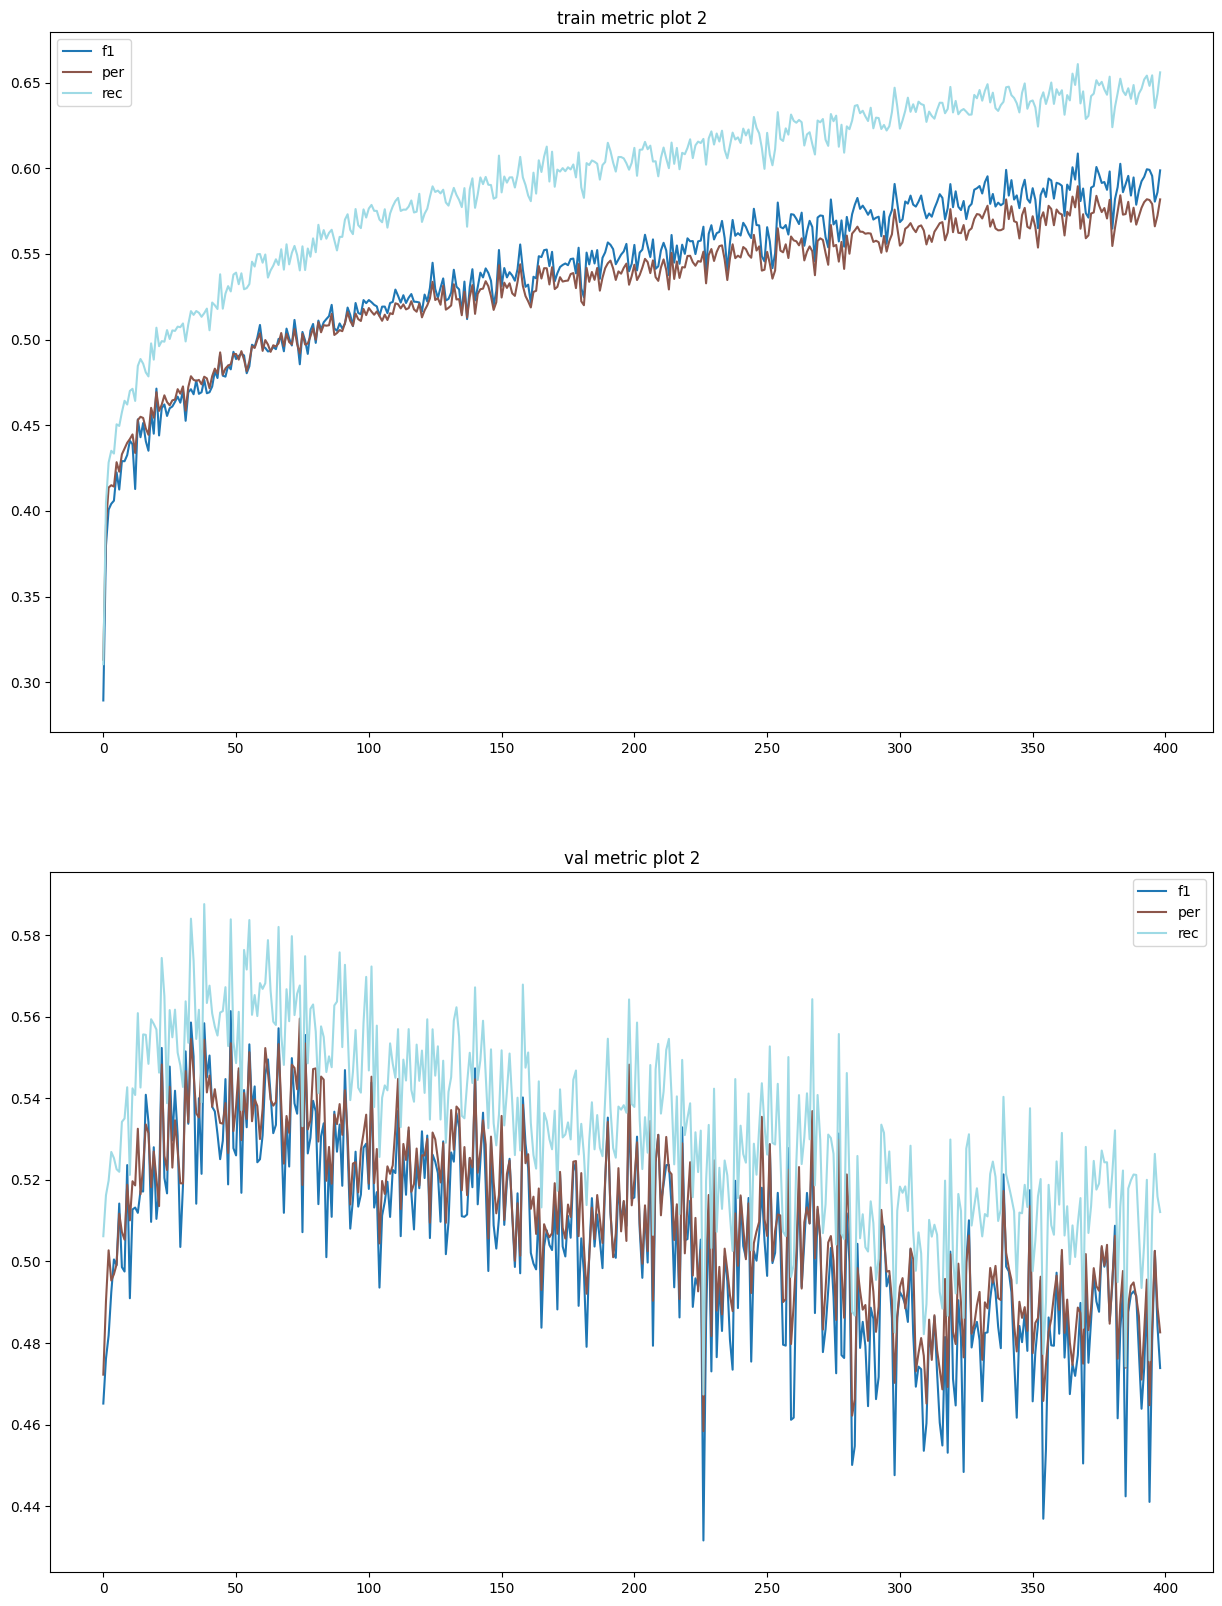

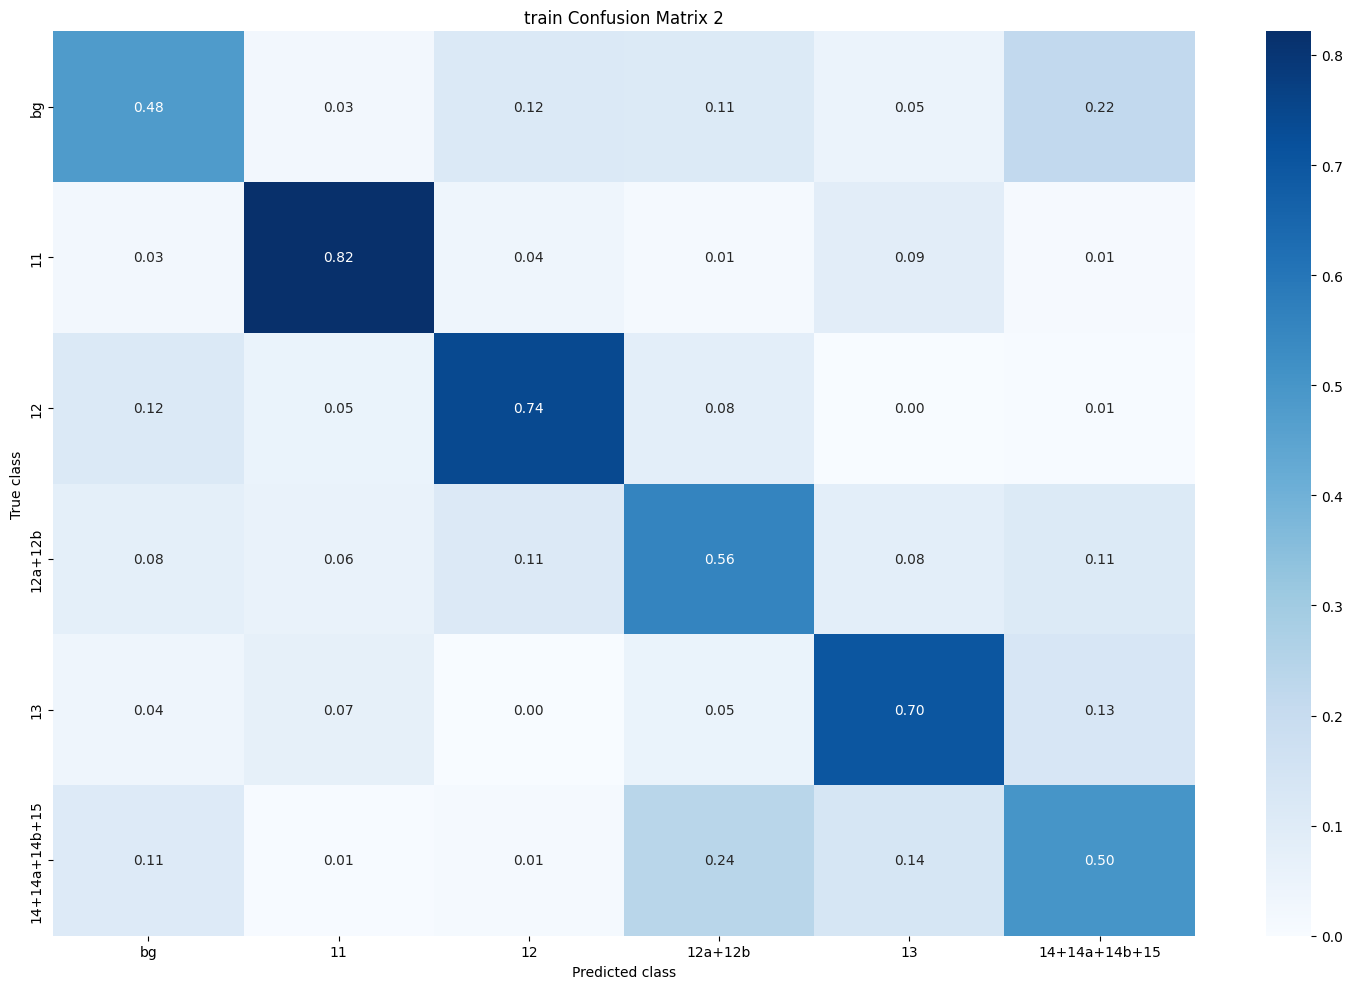

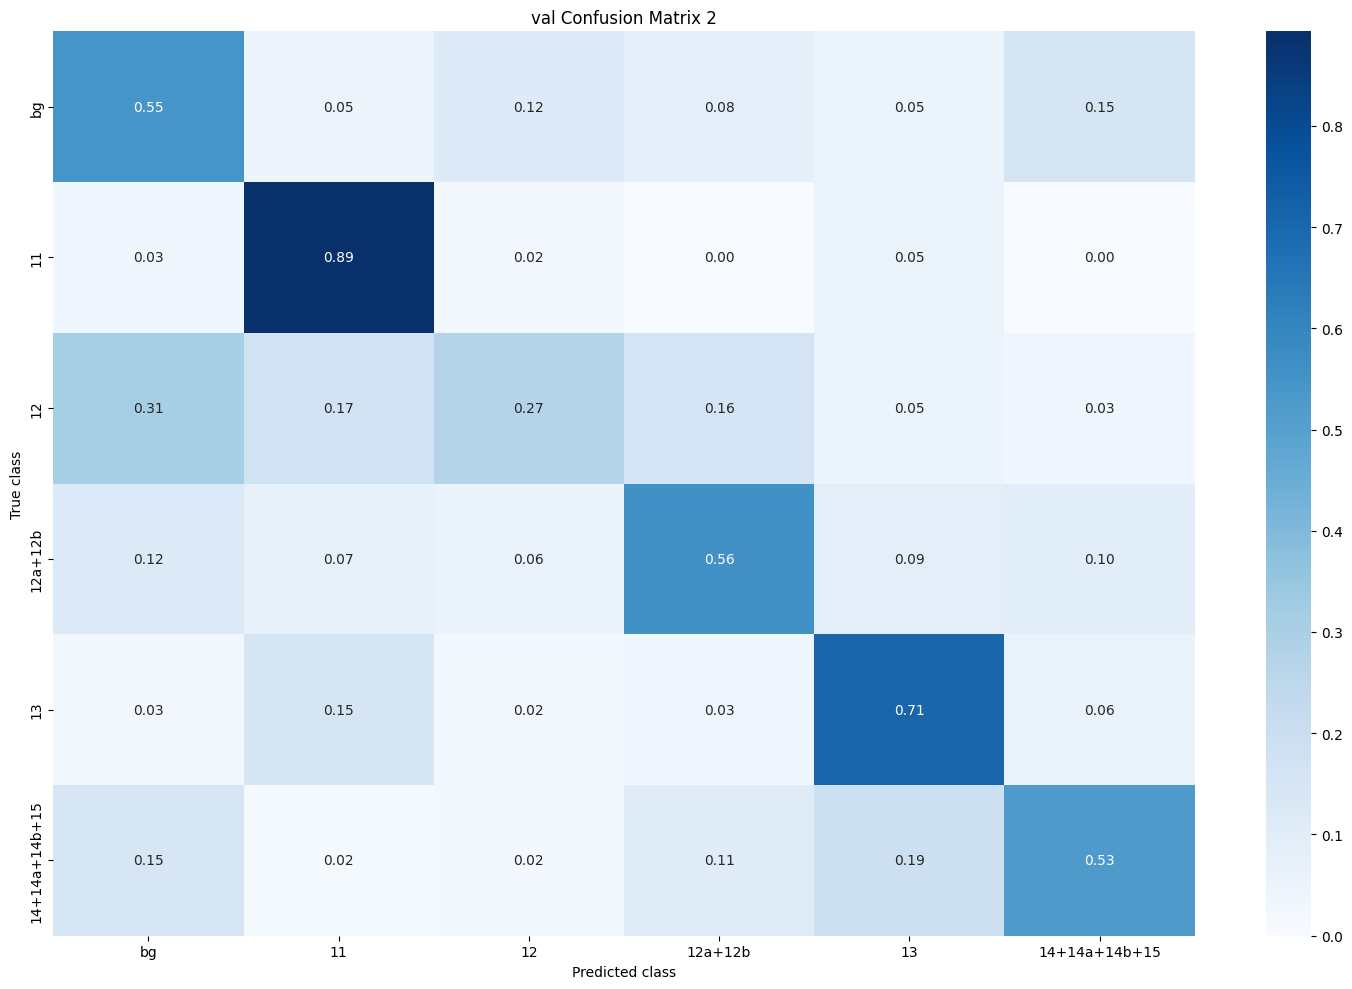

In [25]:
save_full_report(
    restult_sets = restult_sets ,
    training_results = results,
    args = args,
    chosen_index=chosen_index,
    class_maps = class_maps,
    models_label_predictions = models_label_predictions
)
#0.611007159